# ELEC5304 Project 2

**Group 45**

Name: Jinhao Zheng

Name: Yilin Wu

Name: Huiwen Zhang

Name: Yiqian Guo

Name: Chengnan Zhu

1. Download the CIFAR-10 dataset.
2. Split the dataset into training and testing sets using an 80%:20% ratio.
3. Design a neural network suitable for this classification task.
4. Train the network and evaluate its performance.

(i) The primary objective is to achieve more than 80% test accuracy.

(ii) After completing the initial training, you should further improve your network architecture and training strategy so that the model can achieve at least 70% test accuracy within 1 minute of training on a T4 GPU.

In [1]:
# import library
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
import time
import matplotlib.pyplot as plt
from datasets import load_dataset
import numpy as np
from PIL import Image

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# 1. Download dataset

In [3]:
# Load CIFAR-10 from Hugging Face
ds = load_dataset("uoft-cs/cifar10")

# Convert to NumPy arrays
x_train = np.array([np.array(img) for img in ds["train"]["img"]])
y_train0 = np.array(ds["train"]["label"])

x_test = np.array([np.array(img) for img in ds["test"]["img"]])
y_test = np.array(ds["test"]["label"])

print(x_train.shape) # (50000, 32, 32, 3)
print(y_train0.shape) # (50000,)
print(x_test.shape) # (10000, 32, 32, 3)
print(y_test.shape) # (10000,)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/120M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/23.9M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

(50000, 32, 32, 3)
(50000,)
(10000, 32, 32, 3)
(10000,)


# 2. Split the dataset

In [4]:
# spilt 8:2
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train0, test_size=0.2, random_state=5304,
    shuffle=True, stratify=y_train0)

print(f"train set size: {len(x_train)}")
print(f"test set size: {len(x_test)}")

train set size: 40000
test set size: 10000


In [5]:
# Transforms
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

In [6]:
class CifarSub(Dataset):
    def __init__(self, x, y, transform=None):
        self.x = x
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        img = Image.fromarray(self.x[idx])
        label = int(self.y[idx])

        if self.transform is not None:
            img = self.transform(img)

        return img, label

In [7]:
# train Loader
train_loader = DataLoader(
    CifarSub(x_train, y_train, transform=transform_train),
    batch_size=512, shuffle=True, num_workers=2, pin_memory=True)

# test Loader
test_loader = DataLoader(
    CifarSub(x_test, y_test, transform=transform_test),
    batch_size=512, shuffle=False, num_workers=2, pin_memory=True)

# 3. Neural Network

In [8]:
# ResNet 9
def conv_block(in_channels, out_channels, pool=False):
    layers = [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
              nn.BatchNorm2d(out_channels),
              nn.ReLU(inplace=True)]
    if pool: layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class ResNet9(nn.Module):
    def __init__(self):
        super().__init__()
        self.prep = conv_block(3, 32)

        self.layer1 = conv_block(32, 64, pool=True)
        self.res1 = nn.Sequential(conv_block(64, 64), conv_block(64,64))

        self.layer2 = conv_block(64, 128, pool=True)

        self.layer3 = conv_block(128, 256, pool=True)
        self.res3 = nn.Sequential(conv_block(256, 256), conv_block(256,256))

        self.classifier = nn.Sequential(
            nn.AdaptiveMaxPool2d(1),
            nn.Flatten(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.prep(x)
        x = self.layer1(x)
        x = self.res1(x) + x

        x = self.layer2(x)

        x = self.layer3(x)
        x = self.res3(x) + x
        return self.classifier(x)

model = ResNet9().to(device)

# 4. Train and Evaluate


In [9]:
# Parametes
epochs = 15
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.003, weight_decay=5e-3)

scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=0.006, epochs=epochs,
    steps_per_epoch=len(train_loader),
    pct_start=0.04)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

In [10]:
# Train and Teset
start_time = time.time()
test_acc_history = []
best_acc60 = 0

# train
for epoch in range(epochs):
    model.train()

    for inputs, targets in train_loader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda"):
            outputs = model(inputs)
            loss = criterion(outputs, targets)

        old_scale = scaler.get_scale()

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        new_scale = scaler.get_scale()
        if new_scale >= old_scale:
            scheduler.step()

    # testing from epoch 3
    if epoch >= 2:
        model.eval()
        correct, total = 0, 0

        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs = inputs.to(device, non_blocking=True)
                targets = targets.to(device, non_blocking=True)

                with torch.autocast(device_type="cuda"):
                    outputs = model(inputs)

                correct += outputs.argmax(1).eq(targets).sum().item()
                total += targets.size(0)

        acc = 100. * correct / total
        test_acc_history.append(acc)

        spend_time = time.time() - start_time
        if spend_time <= 60:
            best_acc60 = max(best_acc60, acc)

        print(f"Epoch {epoch+1}, time: {spend_time:5.1f}s, acc: {acc:5.2f}%")
    else:
        spend_time = time.time() - start_time
        print(f"Epoch {epoch+1}, time: {spend_time:5.1f}s, acc: not tested")


Epoch 1, time:  15.1s, acc: not tested
Epoch 2, time:  27.9s, acc: not tested
Epoch 3, time:  43.9s, acc: 65.01%
Epoch 4, time:  58.7s, acc: 70.29%
Epoch 5, time:  73.7s, acc: 75.76%
Epoch 6, time:  95.5s, acc: 80.17%
Epoch 7, time: 110.7s, acc: 79.39%
Epoch 8, time: 126.0s, acc: 84.44%
Epoch 9, time: 141.4s, acc: 84.69%
Epoch 10, time: 156.8s, acc: 86.33%
Epoch 11, time: 171.8s, acc: 87.89%
Epoch 12, time: 187.6s, acc: 88.71%
Epoch 13, time: 205.0s, acc: 88.89%
Epoch 14, time: 221.0s, acc: 89.20%
Epoch 15, time: 235.9s, acc: 89.35%


Best accuracy within 60s: 70.29%
Best accuracy: 89.35%


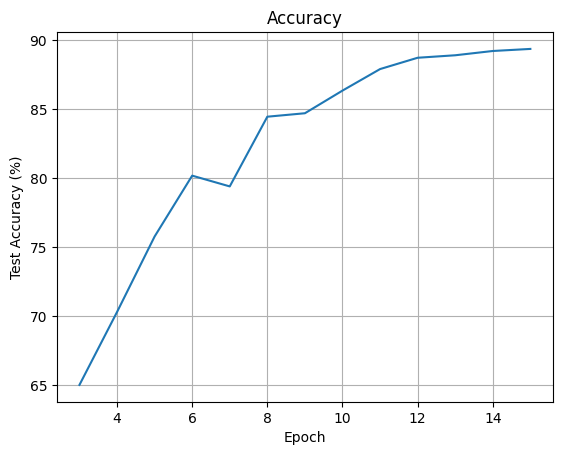

In [11]:
print(f"Best accuracy within 60s: {best_acc60:.2f}%")
print(f"Best accuracy: {max(test_acc_history):.2f}%")

# accuracy plot
plt.plot(range(3, epochs+1), test_acc_history)
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel("Test Accuracy (%)")
plt.grid(True)
plt.show()

The dataset was then normalized using the mean and standard deviation calculated from former researcher. For the network architecture, our group initially planned to design two separate neural networks to satisfy different requirements. However, after several rounds of training and experimentation, we found that a network capable of reaching 70% accuracy within one minute could also achieve over 80% accuracy after full training. Moreover, this model often met the required accuracy more quickly. Therefore, we removed the CNN model that was originally intended as a baseline and directly adopted the more efficient ResNet-9 architecture to complete both tasks simultaneously.

To meet the accuracy requirement within one minute on a T4 GPU, the model needed to reach the target performance within approximately three to four epochs. Since the requirement focuses on training time within one minute, we started accuracy test from the third epoch to reduce unnecessary time consumption (We think a better approach might be to design a trainer that only trains for one minute and then tests, but the current overall design is already capable of accomplishing the task).

We chose ResNet-9 because it is lightweight and can achieve relatively high accuracy within a short training time. In terms of architecture, we first used fully connected layers to compress the image features, which reduced the number of parameters, lowered the risk of overfitting, and improved the speed of each iteration. We then introduced residual connections to address the degradation problem in deeper networks and improve training stability. These skip connections also help reduce gradient loss during backpropagation, allowing information to flow more effectively to shallower layers. As a result, the model can converge rapidly during the first few epochs.

In terms of training strategy, we selected the AdamW optimizer, which can more effectively reduce overfitting on small image datasets such as CIFAR-10. We also used the OneCycleLR learning rate scheduler, which applies a relatively large learning rate in the early stage to help the model quickly move beyond poor local optima and meet the accuracy requirement within one minute. Although the pct_start setting may cause a temporary decrease in intermediate accuracy, it does not significantly affect the final performance. To further improve training speed, we enabled automatic mixed precision training through AMP, which makes full use of the Tensor Cores on the T4 GPU and accelerates training without sacrificing classification accuracy.

Overall, our final design achieves a strong balance between computational efficiency and accuracy by combining architectural simplification through ResNet-9, an aggressive learning rate strategy through OneCycleLR, and low-level acceleration through AMP. This approach is well suited to the CIFAR-10 classification task and successfully completes both challenges required in the project. Ultimately, while maintaining a final accuracy above 80%, the model is also able to reach over 70% accuracy within approximately one minute. In our experiments, the 3rd and 4th epochs, including testing time, occasionally exceeded one minute by a small margin, but the accuracy was consistently above 70%. This demonstrates that the network is fully capable of exceeding the 70% accuracy requirement within the given time constraint.

The results of two representative experiments are shown below:


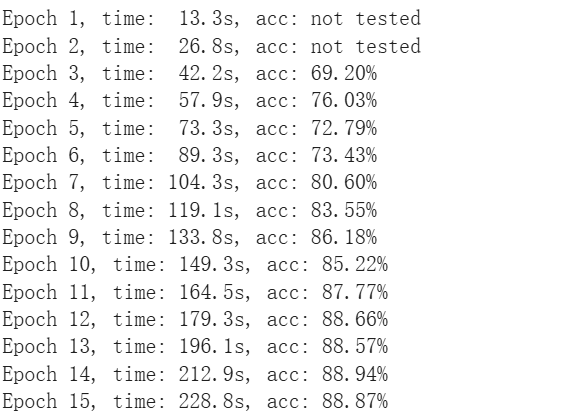

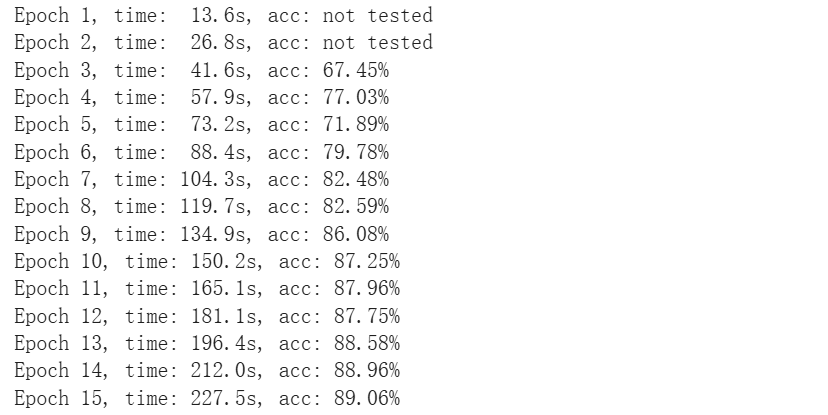

# Task 2: Questions
What kind of neural network architecture is more suitable for learning under limited training time? Why?

With limited training time, it is more suitable for lightweight, computationally efficient and easy-to-optimize neural network structures, such as shallow residual networks such as ResNet-9. First of all, the lightweight model has fewer parameters, and the calculation cost required for forward propagation and reverse propagation is lower, so more training iterations can be completed in the same time, so that the model can learn the edges, textures and category characteristics in the image faster. Secondly, although the structure of ResNet-9 is not deep, it still contains residual connections, which can directly transmit shallow features to deeper layers, improve gradient propagation, reduce gradient disappearance and network degradation during training, and thus improve the convergence speed of the model in the first few epoches. In contrast, although networks that are too deep or too complex may achieve higher accuracy after long-term training, they usually require more computing resources and more epoch to fully converge, which is not ideal under strict time limits such as one minute. Therefore, ResNet-9 can achieve a good balance between training speed, model complexity and classification accuracy, and is more suitable for completing image classification tasks such as CIFAR-10 in a limited training time.

Apart from ResNet-9, other lightweight network architectures are also applicable under the constraint of limited training time. For instance, shallower convolutional neural network (CNN) can achieve very fast training speeds due to their lower computational complexity, but their final accuracy is usually lower than that of residual networks. Additionally, models like MobileNet significantly reduce the number of parameters and computational load by employing depthwise separable convolution, thus offering high efficiency in both rapid training and inference. EfficientNet, on the other hand, achieves a balance among network depth, width, and input resolution to attain high accuracy with fewer parameters, though its structure is relatively more complex. Compared to these methods, ResNet-9 strikes a better balance between training speed, model complexity, and classification accuracy, making it more suitable for this task under strict time constraints.